In [1]:
import sys
import pandas as pd
import numpy as np
import yfinance as yf

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("yfinance version:", yf.__version__)

Python version: 3.13.7 (v3.13.7:bcee1c32211, Aug 14 2025, 19:10:51) [Clang 16.0.0 (clang-1600.0.26.6)]
Pandas version: 3.0.6
NumPy version: 2.5.4
yfinance version: 1.7.0


In [2]:
import yfinance as yf

for ticker in ["SPY", "QQQ"]:
    data = yf.download(
        ticker,
        period="60d",
        interval="5m",
        progress=False,
        auto_adjust=False
    )

    print(f"\n{ticker}")
    print("Rows:", len(data))
    if not data.empty:
        print("First timestamp:", data.index.min())
        print("Last timestamp:", data.index.max())
        print(data.head(3))
    else:
        print("No data returned.")


SPY
Rows: 4680
First timestamp: 2026-07-24 09:30:00-04:00
Last timestamp: 2026-10-16 15:55:00-04:00
Price                       Adj Close       Close        High         Low  \
Ticker                            SPY         SPY         SPY         SPY   
Datetime                                                                    
2026-07-24 09:30:00-04:00  739.277100  739.277100  739.500000  738.419983   
2026-07-24 09:35:00-04:00  739.109985  739.109985  739.659973  738.880005   
2026-07-24 09:40:00-04:00  738.810120  738.810120  739.140076  738.659973   

Price                            Open   Volume  
Ticker                            SPY      SPY  
Datetime                                        
2026-07-24 09:30:00-04:00  738.510010  1467113  
2026-07-24 09:35:00-04:00  739.289978   415105  
2026-07-24 09:40:00-04:00  739.099976   406628  

QQQ
Rows: 4680
First timestamp: 2026-07-24 09:30:00-04:00
Last timestamp: 2026-10-16 15:55:00-04:00
Price                       Adj Close    

In [4]:
from pathlib import Path
import pandas as pd

data_folder = Path("data")

qqq = pd.read_csv(data_folder / "QQQ_clean_1min.csv")
spy = pd.read_csv(data_folder / "SPY_clean_1min.csv")

for name, df in [("QQQ", qqq), ("SPY", spy)]:
    df["datetime"] = pd.to_datetime(df["datetime"])

    print(f"\n{name}")
    print("Rows:", len(df))
    print("First date:", df["datetime"].min())
    print("Last date:", df["datetime"].max())
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate timestamps:", df["datetime"].duplicated().sum())


QQQ
Rows: 435158
First date: 2022-03-07 09:30:00
Last date: 2026-10-16 15:59:00
Missing values: 0
Duplicate timestamps: 0

SPY
Rows: 438433
First date: 2022-03-07 09:32:00
Last date: 2026-10-16 15:59:00
Missing values: 0
Duplicate timestamps: 0


In [5]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    df = df.sort_values("datetime").copy()
    gaps = df["datetime"].diff()

    print(f"\n{name}")
    print("Largest time gap:", gaps.max())
    print("Gaps longer than 2 minutes:", (gaps > pd.Timedelta(minutes=2)).sum())


QQQ
Largest time gap: 3 days 19:38:00
Gaps longer than 2 minutes: 3933

SPY
Largest time gap: 3 days 19:47:00
Gaps longer than 2 minutes: 3615


In [6]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    df = df.sort_values("datetime").copy()
    df["date"] = df["datetime"].dt.date
    df["time"] = df["datetime"].dt.time

    # Count observations per trading date
    counts = df.groupby("date").size()

    print(f"\n{name}")
    print("Trading dates:", len(counts))
    print("Median rows per date:", counts.median())
    print("Dates with fewer than 300 rows:", (counts < 300).sum())
    print("Dates with more than 400 rows:", (counts > 400).sum())


QQQ
Trading dates: 1159
Median rows per date: 378.0
Dates with fewer than 300 rows: 10
Dates with more than 400 rows: 0

SPY
Trading dates: 1159
Median rows per date: 381.0
Dates with fewer than 300 rows: 10
Dates with more than 400 rows: 0


In [7]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    daily_counts = df.groupby(df["datetime"].dt.date).size()
    short_days = daily_counts[daily_counts < 300]

    print(f"\n{name} — dates with fewer than 300 rows")
    print(short_days.to_string())


QQQ — dates with fewer than 300 rows
datetime
2022-11-25    204
2023-07-03    205
2023-11-24    205
2024-07-03    211
2024-11-29    208
2024-12-23     52
2024-12-24    203
2025-07-03    218
2025-11-28    229
2025-12-24    217

SPY — dates with fewer than 300 rows
datetime
2022-11-25    204
2023-07-03    211
2023-11-24    205
2024-07-03    205
2024-11-29    204
2024-12-23     60
2024-12-24    203
2025-07-03    215
2025-11-28    215
2025-12-24    213


In [8]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    day = df[df["datetime"].dt.date.astype(str) == "2024-12-23"]

    print(f"\n{name} — 2024-12-23")
    print("First timestamp:", day["datetime"].min())
    print("Last timestamp:", day["datetime"].max())
    print("Rows:", len(day))
    print(day[["datetime", "Open", "High", "Low", "Close"]].head())


QQQ — 2024-12-23
First timestamp: 2024-12-23 09:30:00
Last timestamp: 2024-12-23 10:22:00
Rows: 52
                  datetime     Open     High      Low    Close
263947 2024-12-23 09:30:00  519.510  520.280  519.300  520.280
263948 2024-12-23 09:31:00  520.320  520.385  519.505  519.950
263949 2024-12-23 09:32:00  519.955  520.215  519.825  520.215
263950 2024-12-23 09:33:00  520.400  520.740  520.175  520.495
263951 2024-12-23 09:34:00  520.410  520.640  520.070  520.110

SPY — 2024-12-23
First timestamp: 2024-12-23 09:30:00
Last timestamp: 2024-12-23 13:33:00
Rows: 60
                  datetime     Open     High      Low    Close
266475 2024-12-23 09:30:00  590.900  591.685  590.740  591.605
266476 2024-12-23 09:31:00  591.760  591.770  591.075  591.610
266477 2024-12-23 09:32:00  591.625  591.680  591.440  591.675
266478 2024-12-23 09:33:00  591.610  591.770  591.510  591.620
266479 2024-12-23 09:34:00  591.595  591.620  591.250  591.255


In [9]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    daily_counts = df.groupby(df["datetime"].dt.date).size()
    suspicious_days = daily_counts[daily_counts < 350]

    print(f"\n{name} — dates with fewer than 350 rows")
    print(suspicious_days.to_string())


QQQ — dates with fewer than 350 rows
datetime
2022-11-25    204
2023-07-03    205
2023-11-24    205
2024-05-03    323
2024-05-08    346
2024-05-10    324
2024-05-13    326
2024-05-14    341
2024-05-16    343
2024-05-24    345
2024-06-14    341
2024-06-24    328
2024-06-26    323
2024-07-01    343
2024-07-03    211
2024-07-26    342
2024-08-21    349
2024-11-29    208
2024-12-23     52
2024-12-24    203
2025-07-03    218
2025-11-28    229
2025-12-04    349
2025-12-24    217
2025-12-30    348

SPY — dates with fewer than 350 rows
datetime
2022-11-25    204
2023-07-03    211
2023-11-24    205
2024-07-03    205
2024-11-29    204
2024-12-23     60
2024-12-24    203
2025-07-03    215
2025-11-28    215
2025-12-24    213


In [10]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    day = df[df["datetime"].dt.date.astype(str) == "2024-05-03"]

    print(f"\n{name} — 2024-05-03")
    print("Rows:", len(day))
    print("First timestamp:", day["datetime"].min())
    print("Last timestamp:", day["datetime"].max())

    print("Largest gap:")
    print(day["datetime"].diff().max())


QQQ — 2024-05-03
Rows: 323
First timestamp: 2024-05-03 09:30:00
Last timestamp: 2024-05-03 15:59:00
Largest gap:
0 days 00:14:00

SPY — 2024-05-03
Rows: 382
First timestamp: 2024-05-03 09:30:00
Last timestamp: 2024-05-03 15:59:00
Largest gap:
0 days 00:07:00


In [11]:
for name, df in [("QQQ", qqq), ("SPY", spy)]:
    day = df[df["datetime"].dt.date.astype(str) == "2024-05-03"]
    day = day.sort_values("datetime")

    expected_minutes = pd.date_range(
        start="2024-05-03 09:30",
        end="2024-05-03 15:59",
        freq="min"
    )

    actual_minutes = pd.DatetimeIndex(day["datetime"])
    missing_minutes = expected_minutes.difference(actual_minutes)

    print(f"\n{name}")
    print("Expected minute timestamps:", len(expected_minutes))
    print("Actual rows:", len(day))
    print("Missing timestamps:", len(missing_minutes))
    print("First missing timestamps:", list(missing_minutes[:10]))


QQQ
Expected minute timestamps: 390
Actual rows: 323
Missing timestamps: 67
First missing timestamps: [Timestamp('2024-05-03 09:53:00'), Timestamp('2024-05-03 09:54:00'), Timestamp('2024-05-03 09:56:00'), Timestamp('2024-05-03 09:57:00'), Timestamp('2024-05-03 09:58:00'), Timestamp('2024-05-03 10:25:00'), Timestamp('2024-05-03 10:26:00'), Timestamp('2024-05-03 10:38:00'), Timestamp('2024-05-03 10:44:00'), Timestamp('2024-05-03 10:45:00')]

SPY
Expected minute timestamps: 390
Actual rows: 382
Missing timestamps: 8
First missing timestamps: [Timestamp('2024-05-03 10:44:00'), Timestamp('2024-05-03 10:45:00'), Timestamp('2024-05-03 10:46:00'), Timestamp('2024-05-03 10:47:00'), Timestamp('2024-05-03 10:48:00'), Timestamp('2024-05-03 10:49:00'), Timestamp('2024-05-03 12:57:00'), Timestamp('2024-05-03 15:34:00')]


In [12]:
from pathlib import Path
import pandas as pd

data_folder = Path("data")

qqq_5m = pd.read_parquet(data_folder / "QQQ_clean_5min.parquet")
spy_5m = pd.read_parquet(data_folder / "SPY_clean_5min.parquet")

for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head(3))

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [13]:
%pip install pyarrow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 6.1 MB/s  0:00:06m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import pandas as pd

data_folder = Path("data")

qqq_5m = pd.read_parquet(data_folder / "QQQ_clean_5min.parquet")
spy_5m = pd.read_parquet(data_folder / "SPY_clean_5min.parquet")

for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    display(df.head(3))


QQQ
Rows: 89745
Columns: ['datetime', 'Open', 'High', 'Low', 'Close', 'Volume', 'source']


,datetime,Open,High,Low,Close,Volume,source
0,2022-03-07 09:30:00,337.33,337.970,336.83,336.87,15672,iex
1,2022-03-07 09:35:00,336.88,338.215,336.52,337.45,22083,iex
2,2022-03-07 09:40:00,337.33,337.410,335.17,335.57,24938,iex



SPY
Rows: 89750
Columns: ['datetime', 'Open', 'High', 'Low', 'Close', 'Volume', 'source']


,datetime,Open,High,Low,Close,Volume,source
0,2022-03-07 09:30:00,431.72,431.810,430.295,430.42,25845,iex
1,2022-03-07 09:35:00,430.29,430.800,429.780,430.21,34633,iex
2,2022-03-07 09:40:00,430.26,430.575,428.610,428.95,23703,iex


In [3]:
for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])
    df = df.sort_values("datetime")

    print(f"\n{name}")
    print("First timestamp:", df["datetime"].min())
    print("Last timestamp:", df["datetime"].max())
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate timestamps:", df["datetime"].duplicated().sum())
    print("Unique trading dates:", df["datetime"].dt.date.nunique())


QQQ
First timestamp: 2022-03-07 09:30:00
Last timestamp: 2026-10-16 15:55:00
Missing values: 0
Duplicate timestamps: 0
Unique trading dates: 1159

SPY
First timestamp: 2022-03-07 09:30:00
Last timestamp: 2026-10-16 15:55:00
Missing values: 0
Duplicate timestamps: 0
Unique trading dates: 1159


In [4]:
qqq_times = set(qqq_5m["datetime"])
spy_times = set(spy_5m["datetime"])

print("Timestamps shared by both:", len(qqq_times & spy_times))
print("Only in QQQ:", len(qqq_times - spy_times))
print("Only in SPY:", len(spy_times - qqq_times))

print("\nTimestamps only in QQQ:")
print(sorted(qqq_times - spy_times)[:10])

print("\nTimestamps only in SPY:")
print(sorted(spy_times - qqq_times)[:10])

Timestamps shared by both: 89537
Only in QQQ: 208
Only in SPY: 213

Timestamps only in QQQ:
[Timestamp('2022-03-10 12:25:00'), Timestamp('2022-03-21 09:35:00'), Timestamp('2022-03-24 14:45:00'), Timestamp('2022-03-30 12:00:00'), Timestamp('2022-04-04 10:15:00'), Timestamp('2022-04-13 10:10:00'), Timestamp('2022-04-14 15:55:00'), Timestamp('2022-04-20 09:30:00'), Timestamp('2022-04-20 09:35:00'), Timestamp('2022-05-02 09:35:00')]

Timestamps only in SPY:
[Timestamp('2022-03-09 13:05:00'), Timestamp('2022-03-23 10:45:00'), Timestamp('2022-04-20 13:45:00'), Timestamp('2022-04-22 14:20:00'), Timestamp('2022-05-03 10:00:00'), Timestamp('2022-05-11 09:35:00'), Timestamp('2022-06-08 13:35:00'), Timestamp('2022-06-10 13:50:00'), Timestamp('2022-06-14 09:30:00'), Timestamp('2022-06-22 14:15:00')]


In [5]:
qqq_only = pd.DataFrame({
    "datetime": sorted(qqq_times - spy_times)
})

spy_only = pd.DataFrame({
    "datetime": sorted(spy_times - qqq_times)
})

qqq_only["date"] = qqq_only["datetime"].dt.date
spy_only["date"] = spy_only["datetime"].dt.date

print("Dates with QQQ-only timestamps:", qqq_only["date"].nunique())
print("Dates with SPY-only timestamps:", spy_only["date"].nunique())

print("\nDays with the most QQQ-only timestamps:")
print(qqq_only.groupby("date").size().sort_values(ascending=False).head(10))

print("\nDays with the most SPY-only timestamps:")
print(spy_only.groupby("date").size().sort_values(ascending=False).head(10))

Dates with QQQ-only timestamps: 166
Dates with SPY-only timestamps: 179

Days with the most QQQ-only timestamps:
date
2025-11-28    6
2023-05-22    4
2025-12-24    4
2024-11-29    4
2025-07-03    4
2024-06-07    4
2023-03-13    3
2022-05-24    3
2025-08-05    2
2025-11-03    2
dtype: int64

Days with the most SPY-only timestamps:
date
2024-12-23    5
2026-04-23    3
2025-08-13    3
2022-11-25    3
2023-05-16    3
2025-12-04    3
2025-12-30    3
2023-02-16    2
2022-11-09    2
2024-11-13    2
dtype: int64


In [6]:
print("QQQ-only timestamps by time:")
print(qqq_only["datetime"].dt.strftime("%H:%M").value_counts().head(15))

print("\nSPY-only timestamps by time:")
print(spy_only["datetime"].dt.strftime("%H:%M").value_counts().head(15))

QQQ-only timestamps by time:
datetime
09:30    16
09:35     9
15:55     7
12:25     6
12:00     5
13:20     5
10:30     5
13:10     5
11:40     5
10:10     4
14:50     4
12:55     4
11:30     4
13:35     4
14:15     4
Name: count, dtype: int64

SPY-only timestamps by time:
datetime
09:30    27
09:35    10
15:55    10
13:00     9
13:05     7
14:20     6
13:55     5
12:55     5
11:45     5
10:45     4
13:45     4
13:35     4
14:35     4
13:30     4
13:20     4
Name: count, dtype: int64


In [7]:
# Inspect the first five QQQ-only timestamps in the QQQ dataset
for ts in sorted(qqq_times - spy_times)[:5]:
    print(f"\nQQQ-only timestamp: {ts}")
    print(
        qqq_5m.loc[
            qqq_5m["datetime"].between(
                ts - pd.Timedelta(minutes=10),
                ts + pd.Timedelta(minutes=10)
            ),
            ["datetime", "Open", "High", "Low", "Close", "Volume"]
        ].to_string(index=False)
    )


QQQ-only timestamp: 2022-03-10 12:25:00
           datetime    Open    High     Low   Close  Volume
2022-03-10 12:15:00 328.290 328.380 328.080 328.360    1599
2022-03-10 12:20:00 328.510 329.010 328.270 328.950    2224
2022-03-10 12:25:00 329.030 329.040 328.870 328.870    1305
2022-03-10 12:30:00 328.975 328.975 328.470 328.490    4154
2022-03-10 12:35:00 328.410 328.410 327.865 327.865    9044

QQQ-only timestamp: 2022-03-21 09:35:00
           datetime    Open   High    Low  Close  Volume
2022-03-21 09:30:00 350.155 350.99 349.88 350.95   25170
2022-03-21 09:35:00 350.940 351.50 350.63 351.49   15536
2022-03-21 09:40:00 351.520 352.46 351.52 351.75   25303
2022-03-21 09:45:00 351.860 351.90 350.04 350.12   10636

QQQ-only timestamp: 2022-03-24 14:45:00
           datetime   Open   High     Low   Close  Volume
2022-03-24 14:35:00 356.81 356.81 356.600 356.760    1726
2022-03-24 14:40:00 356.91 356.96 356.725 356.945    3475
2022-03-24 14:45:00 356.72 356.79 356.550 356.690    2255


In [8]:
for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    df = df.sort_values("datetime").copy()
    df["date"] = df["datetime"].dt.date
    df["time_diff"] = df.groupby("date")["datetime"].diff()

    print(f"\n{name}")
    print("Intervals longer than 5 minutes within a day:",
          (df["time_diff"] > pd.Timedelta(minutes=5)).sum())

    print("Largest within-day interval:",
          df.groupby("date")["time_diff"].max().max())


QQQ
Intervals longer than 5 minutes within a day: 234
Largest within-day interval: 0 days 00:30:00

SPY
Intervals longer than 5 minutes within a day: 235
Largest within-day interval: 0 days 01:45:00


In [9]:
for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    df = df.sort_values("datetime").copy()
    df["date"] = df["datetime"].dt.date
    df["time_diff"] = df.groupby("date")["datetime"].diff()

    gaps = df.loc[
        df["time_diff"] > pd.Timedelta(minutes=5),
        ["datetime", "time_diff"]
    ]

    print(f"\n{name} — 10 largest gaps:")
    print(
        gaps.sort_values("time_diff", ascending=False)
        .head(10)
        .to_string(index=False)
    )


QQQ — 10 largest gaps:
           datetime       time_diff
2025-12-24 13:55:00 0 days 00:30:00
2023-10-13 13:40:00 0 days 00:15:00
2024-03-20 10:35:00 0 days 00:15:00
2025-08-13 13:30:00 0 days 00:15:00
2025-12-02 10:40:00 0 days 00:15:00
2023-01-17 14:25:00 0 days 00:15:00
2025-12-04 14:30:00 0 days 00:15:00
2025-12-30 09:45:00 0 days 00:15:00
2022-11-25 13:25:00 0 days 00:15:00
2022-11-25 13:10:00 0 days 00:15:00

SPY — 10 largest gaps:
           datetime       time_diff
2024-12-23 12:05:00 0 days 01:45:00
2024-12-23 13:30:00 0 days 00:55:00
2025-11-28 13:40:00 0 days 00:30:00
2025-07-03 13:30:00 0 days 00:20:00
2026-05-01 11:50:00 0 days 00:15:00
2023-05-08 14:20:00 0 days 00:15:00
2023-05-22 10:55:00 0 days 00:15:00
2025-08-05 12:50:00 0 days 00:15:00
2023-01-17 14:25:00 0 days 00:15:00
2024-12-23 12:35:00 0 days 00:15:00


In [10]:
for name, df, date in [
    ("SPY", spy_5m, "2024-12-23"),
    ("QQQ", qqq_5m, "2025-12-24"),
]:
    print(f"\n{name} — {date}")

    day = df[df["datetime"].dt.strftime("%Y-%m-%d") == date]

    print(day[["datetime", "Open", "High", "Low", "Close", "Volume"]]
          .to_string(index=False))


SPY — 2024-12-23
           datetime    Open    High     Low   Close  Volume
2024-12-23 09:30:00 590.900 591.770 590.740 591.255   25112
2024-12-23 09:35:00 591.220 591.610 590.655 591.230   18852
2024-12-23 09:40:00 591.260 591.380 590.500 590.580    8060
2024-12-23 09:45:00 590.520 590.810 589.630 590.000    5787
2024-12-23 09:50:00 590.000 590.010 589.180 589.930    4998
2024-12-23 09:55:00 589.910 590.730 589.700 590.010    5915
2024-12-23 10:00:00 590.020 590.440 589.350 589.540    5390
2024-12-23 10:05:00 589.510 590.005 588.390 588.390    1976
2024-12-23 10:10:00 590.000 590.000 587.760 588.830    6760
2024-12-23 10:15:00 589.010 590.005 588.840 590.000    9353
2024-12-23 10:20:00 589.080 590.010 588.880 589.060    1772
2024-12-23 12:05:00 592.150 592.290 592.150 592.290      23
2024-12-23 12:10:00 592.355 592.385 592.060 592.060      18
2024-12-23 12:20:00 591.990 591.990 591.990 591.990     100
2024-12-23 12:35:00 592.475 592.475 592.475 592.475       2
2024-12-23 13:30:00 59

In [11]:
for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])

    # Keep regular-session bar timestamps: 09:30 through 15:55
    regular = df[
        (df["datetime"].dt.strftime("%H:%M") >= "09:30") &
        (df["datetime"].dt.strftime("%H:%M") <= "15:55")
    ].copy()

    bars_per_day = regular.groupby(
        regular["datetime"].dt.date
    ).size()

    print(f"\n{name}")
    print("Trading days:", len(bars_per_day))
    print("Days with fewer than 60 bars:", (bars_per_day < 60).sum())
    print("Minimum bars in a day:", bars_per_day.min())
    print("Median bars per day:", bars_per_day.median())

    print("\n10 days with the fewest bars:")
    print(bars_per_day.sort_values().head(10))


QQQ
Trading days: 1159
Days with fewer than 60 bars: 10
Minimum bars in a day: 11
Median bars per day: 78.0

10 days with the fewest bars:
datetime
2024-12-23    11
2023-11-24    42
2024-12-24    42
2023-07-03    43
2024-07-03    44
2024-11-29    45
2022-11-25    45
2025-12-24    48
2025-07-03    49
2025-11-28    53
dtype: int64

SPY
Trading days: 1159
Days with fewer than 60 bars: 10
Minimum bars in a day: 16
Median bars per day: 78.0

10 days with the fewest bars:
datetime
2024-12-23    16
2024-11-29    41
2024-12-24    42
2024-07-03    43
2023-11-24    43
2023-07-03    44
2025-12-24    44
2022-11-25    46
2025-07-03    47
2025-11-28    47
dtype: int64


In [12]:
for date in ["2024-12-23", "2024-12-24", "2025-12-24"]:
    print(f"\n{date}")

    for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
        day = df[
            df["datetime"].dt.strftime("%Y-%m-%d") == date
        ].sort_values("datetime")

        print(
            f"{name}: {len(day)} bars, "
            f"first={day['datetime'].min()}, "
            f"last={day['datetime'].max()}"
        )


2024-12-23
QQQ: 11 bars, first=2024-12-23 09:30:00, last=2024-12-23 10:20:00
SPY: 16 bars, first=2024-12-23 09:30:00, last=2024-12-23 13:30:00

2024-12-24
QQQ: 42 bars, first=2024-12-24 09:30:00, last=2024-12-24 12:55:00
SPY: 42 bars, first=2024-12-24 09:30:00, last=2024-12-24 12:55:00

2025-12-24
QQQ: 48 bars, first=2025-12-24 09:30:00, last=2025-12-24 13:55:00
SPY: 44 bars, first=2025-12-24 09:30:00, last=2025-12-24 13:05:00


In [13]:
print("QQQ datetime dtype:", qqq_5m["datetime"].dtype)
print("SPY datetime dtype:", spy_5m["datetime"].dtype)

print("\nQQQ first timestamps:")
print(qqq_5m["datetime"].head())

print("\nQQQ last timestamps on 24 Dec 2025:")
print(
    qqq_5m[
        qqq_5m["datetime"].dt.strftime("%Y-%m-%d") == "2025-12-24"
    ]["datetime"].tail(10)
)

QQQ datetime dtype: datetime64[ns]
SPY datetime dtype: datetime64[ns]

QQQ first timestamps:
0   2022-03-07 09:30:00
1   2022-03-07 09:35:00
2   2022-03-07 09:40:00
3   2022-03-07 09:45:00
4   2022-03-07 09:50:00
Name: datetime, dtype: datetime64[ns]

QQQ last timestamps on 24 Dec 2025:
73952   2025-12-24 12:40:00
73953   2025-12-24 12:45:00
73954   2025-12-24 12:50:00
73955   2025-12-24 12:55:00
73956   2025-12-24 13:00:00
73957   2025-12-24 13:05:00
73958   2025-12-24 13:10:00
73959   2025-12-24 13:15:00
73960   2025-12-24 13:25:00
73961   2025-12-24 13:55:00
Name: datetime, dtype: datetime64[ns]


In [14]:
for name, df, date in [
    ("QQQ", qqq_5m, "2025-12-24"),
    ("SPY", spy_5m, "2025-12-24"),
    ("QQQ", qqq_5m, "2024-12-24"),
    ("SPY", spy_5m, "2024-12-24"),
]:
    day = df[df["datetime"].dt.strftime("%Y-%m-%d") == date]

    after_close = day[
        day["datetime"].dt.strftime("%H:%M") > "13:00"
    ]

    print(f"\n{name} — {date}")
    print("Bars:", len(day))
    print("Bars after 13:00:", len(after_close))
    print("Timestamps after 13:00:")
    print(after_close["datetime"].to_list())


QQQ — 2025-12-24
Bars: 48
Bars after 13:00: 5
Timestamps after 13:00:
[Timestamp('2025-12-24 13:05:00'), Timestamp('2025-12-24 13:10:00'), Timestamp('2025-12-24 13:15:00'), Timestamp('2025-12-24 13:25:00'), Timestamp('2025-12-24 13:55:00')]

SPY — 2025-12-24
Bars: 44
Bars after 13:00: 1
Timestamps after 13:00:
[Timestamp('2025-12-24 13:05:00')]

QQQ — 2024-12-24
Bars: 42
Bars after 13:00: 0
Timestamps after 13:00:
[]

SPY — 2024-12-24
Bars: 42
Bars after 13:00: 0
Timestamps after 13:00:
[]


In [15]:
from pathlib import Path

data_folder = Path("data")

def keep_regular_session(df):
    df = df.copy()
    times = df["datetime"].dt.strftime("%H:%M")
    return df.loc[
        (times >= "09:30") & (times <= "15:55")
    ].copy()

qqq_regular = keep_regular_session(qqq_5m)
spy_regular = keep_regular_session(spy_5m)

print("QQQ original rows:", len(qqq_5m))
print("QQQ regular-session rows:", len(qqq_regular))

print("\nSPY original rows:", len(spy_5m))
print("SPY regular-session rows:", len(spy_regular))

QQQ original rows: 89745
QQQ regular-session rows: 89745

SPY original rows: 89750
SPY regular-session rows: 89750


In [16]:
for name, df in [("QQQ", qqq_regular), ("SPY", spy_regular)]:
    dates = pd.to_datetime(df["datetime"]).dt.date

    print(f"\n{name}")
    print("First date:", dates.min())
    print("Last date:", dates.max())
    print("Unique dates:", dates.nunique())
    print("Rows:", len(df))


QQQ
First date: 2022-03-07
Last date: 2026-10-16
Unique dates: 1159
Rows: 89745

SPY
First date: 2022-03-07
Last date: 2026-10-16
Unique dates: 1159
Rows: 89750


In [17]:
%pip install pandas_market_calendars

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [pandas_market_calendars]_market_calendars]
Note: you may need to restart the kernel to use updated packages.


In [18]:
import pandas_market_calendars as mcal

nyse = mcal.get_calendar("NYSE")

schedule = nyse.schedule(
    start_date="2022-03-07",
    end_date="2026-10-16"
)

print("Scheduled market sessions:", len(schedule))
print("\nFirst five sessions:")
print(schedule.head())

print("\nEarly-close sessions:")
print(nyse.early_closes(schedule).head(10))

Scheduled market sessions: 1159

First five sessions:
                         market_open              market_close
2022-03-07 2022-03-07 14:30:00+00:00 2022-03-07 21:00:00+00:00
2022-03-08 2022-03-08 14:30:00+00:00 2022-03-08 21:00:00+00:00
2022-03-09 2022-03-09 14:30:00+00:00 2022-03-09 21:00:00+00:00
2022-03-10 2022-03-10 14:30:00+00:00 2022-03-10 21:00:00+00:00
2022-03-11 2022-03-11 14:30:00+00:00 2022-03-11 21:00:00+00:00

Early-close sessions:
                         market_open              market_close
2022-11-25 2022-11-25 14:30:00+00:00 2022-11-25 18:00:00+00:00
2023-07-03 2023-07-03 13:30:00+00:00 2023-07-03 17:00:00+00:00
2023-11-24 2023-11-24 14:30:00+00:00 2023-11-24 18:00:00+00:00
2024-07-03 2024-07-03 13:30:00+00:00 2024-07-03 17:00:00+00:00
2024-11-29 2024-11-29 14:30:00+00:00 2024-11-29 18:00:00+00:00
2024-12-24 2024-12-24 14:30:00+00:00 2024-12-24 18:00:00+00:00
2025-07-03 2025-07-03 13:30:00+00:00 2025-07-03 17:00:00+00:00
2025-11-28 2025-11-28 14:30:00+00:00 2025

In [19]:
def compare_with_calendar(df, schedule, name):
    counts = df.groupby(df["datetime"].dt.date).size()

    expected = pd.DataFrame({
        "date": schedule.index.date,
        "market_open": schedule["market_open"].dt.tz_convert(
            "America/New_York"
        ).dt.tz_localize(None).values,
        "market_close": schedule["market_close"].dt.tz_convert(
            "America/New_York"
        ).dt.tz_localize(None).values,
    })

    expected["expected_bars"] = (
        (expected["market_close"] - expected["market_open"])
        .dt.total_seconds() / 300
    ).astype(int)

    expected["observed_bars"] = expected["date"].map(counts).fillna(0).astype(int)
    expected["difference"] = (
        expected["expected_bars"] - expected["observed_bars"]
    )

    print(f"\n{name}: sessions with fewer bars than expected")
    print(
        expected[expected["difference"] > 0]
        .sort_values("difference", ascending=False)
        .head(15)
        .to_string(index=False)
    )

    print("\nNumber of sessions with fewer bars:", (expected["difference"] > 0).sum())
    print("Number of sessions with more bars:", (expected["difference"] < 0).sum())

    return expected


qqq_calendar_check = compare_with_calendar(qqq_regular, schedule, "QQQ")
spy_calendar_check = compare_with_calendar(spy_regular, schedule, "SPY")


QQQ: sessions with fewer bars than expected
      date         market_open        market_close  expected_bars  observed_bars  difference
2024-12-23 2024-12-23 09:30:00 2024-12-23 16:00:00             78             11          67
2024-03-20 2024-03-20 09:30:00 2024-03-20 16:00:00             78             74           4
2024-07-25 2024-07-25 09:30:00 2024-07-25 16:00:00             78             75           3
2025-08-13 2025-08-13 09:30:00 2025-08-13 16:00:00             78             75           3
2025-12-30 2025-12-30 09:30:00 2025-12-30 16:00:00             78             75           3
2023-05-16 2023-05-16 09:30:00 2023-05-16 16:00:00             78             75           3
2024-04-29 2024-04-29 09:30:00 2024-04-29 16:00:00             78             75           3
2026-04-23 2026-04-23 09:30:00 2026-04-23 16:00:00             78             75           3
2025-12-04 2025-12-04 09:30:00 2025-12-04 16:00:00             78             75           3
2023-04-14 2023-04-14 09:

In [20]:
for name, check in [
    ("QQQ", qqq_calendar_check),
    ("SPY", spy_calendar_check),
]:
    print(f"\n{name} — sessions with more bars than expected")
    print(
        check[check["difference"] < 0][
            ["date", "expected_bars", "observed_bars", "difference"]
        ].to_string(index=False)
    )


QQQ — sessions with more bars than expected
      date  expected_bars  observed_bars  difference
2022-11-25             42             45          -3
2023-07-03             42             43          -1
2024-07-03             42             44          -2
2024-11-29             42             45          -3
2025-07-03             42             49          -7
2025-11-28             42             53         -11
2025-12-24             42             48          -6

SPY — sessions with more bars than expected
      date  expected_bars  observed_bars  difference
2022-11-25             42             46          -4
2023-07-03             42             44          -2
2023-11-24             42             43          -1
2024-07-03             42             43          -1
2025-07-03             42             47          -5
2025-11-28             42             47          -5
2025-12-24             42             44          -2


In [21]:
for name, df in [("QQQ", qqq_5m), ("SPY", spy_5m)]:
    day = df[
        df["datetime"].dt.strftime("%Y-%m-%d") == "2025-11-28"
    ].sort_values("datetime")

    print(f"\n{name} — 2025-11-28")
    print("First timestamps:")
    print(day["datetime"].head(5).to_list())

    print("\nLast timestamps:")
    print(day["datetime"].tail(15).to_list())


QQQ — 2025-11-28
First timestamps:
[Timestamp('2025-11-28 09:30:00'), Timestamp('2025-11-28 09:35:00'), Timestamp('2025-11-28 09:40:00'), Timestamp('2025-11-28 09:45:00'), Timestamp('2025-11-28 09:50:00')]

Last timestamps:
[Timestamp('2025-11-28 12:40:00'), Timestamp('2025-11-28 12:45:00'), Timestamp('2025-11-28 12:50:00'), Timestamp('2025-11-28 12:55:00'), Timestamp('2025-11-28 13:00:00'), Timestamp('2025-11-28 13:05:00'), Timestamp('2025-11-28 13:10:00'), Timestamp('2025-11-28 13:15:00'), Timestamp('2025-11-28 13:20:00'), Timestamp('2025-11-28 13:25:00'), Timestamp('2025-11-28 13:30:00'), Timestamp('2025-11-28 13:35:00'), Timestamp('2025-11-28 13:40:00'), Timestamp('2025-11-28 13:45:00'), Timestamp('2025-11-28 13:55:00')]

SPY — 2025-11-28
First timestamps:
[Timestamp('2025-11-28 09:30:00'), Timestamp('2025-11-28 09:35:00'), Timestamp('2025-11-28 09:40:00'), Timestamp('2025-11-28 09:45:00'), Timestamp('2025-11-28 09:50:00')]

Last timestamps:
[Timestamp('2025-11-28 12:10:00'), Time

In [22]:
def make_calendar_clean(df, schedule):
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])
    df["date"] = df["datetime"].dt.date

    # Build expected five-minute timestamps for each session.
    expected_by_date = {}

    for session_date, row in schedule.iterrows():
        day = session_date.date()
        open_time = row["market_open"].tz_convert(
            "America/New_York"
        ).tz_localize(None)
        close_time = row["market_close"].tz_convert(
            "America/New_York"
        ).tz_localize(None)

        expected_by_date[day] = pd.date_range(
            start=open_time,
            end=close_time - pd.Timedelta(minutes=5),
            freq="5min"
        )

    clean_days = []

    for day, expected_times in expected_by_date.items():
        actual = df[df["date"] == day].set_index("datetime")

        # Retain only timestamps expected during this market session.
        actual = actual.loc[actual.index.intersection(expected_times)]

        # Keep only fully observed sessions for this initial strict dataset.
        if len(actual) == len(expected_times) and actual.index.isin(expected_times).all():
            clean_days.append(actual.reset_index())

    if clean_days:
        return pd.concat(clean_days, ignore_index=True)

    return pd.DataFrame(columns=df.columns)


qqq_clean = make_calendar_clean(qqq_5m, schedule)
spy_clean = make_calendar_clean(spy_5m, schedule)

print("QQQ rows retained:", len(qqq_clean))
print("QQQ dates retained:", qqq_clean["date"].nunique())

print("\nSPY rows retained:", len(spy_clean))
print("SPY dates retained:", spy_clean["date"].nunique())

QQQ rows retained: 70968
QQQ dates retained: 914

SPY rows retained: 71274
SPY dates retained: 917


In [23]:
qqq_dates = set(qqq_clean["date"])
spy_dates = set(spy_clean["date"])

shared_dates = qqq_dates & spy_dates

print("QQQ retained dates:", len(qqq_dates))
print("SPY retained dates:", len(spy_dates))
print("Dates retained by both:", len(shared_dates))
print("Only QQQ retains:", len(qqq_dates - spy_dates))
print("Only SPY retains:", len(spy_dates - qqq_dates))

QQQ retained dates: 914
SPY retained dates: 917
Dates retained by both: 794
Only QQQ retains: 120
Only SPY retains: 123


In [24]:
for name, check in [
    ("QQQ", qqq_calendar_check),
    ("SPY", spy_calendar_check),
]:
    print(f"\n{name}: sessions grouped by missing-bar count")

    missing = check["difference"].clip(lower=0)

    print(
        pd.cut(
            missing,
            bins=[-1, 0, 2, 5, 15, 100],
            labels=[
                "Complete",
                "1–2 missing",
                "3–5 missing",
                "6–15 missing",
                "More than 15 missing"
            ]
        ).value_counts().sort_index()
    )


QQQ: sessions grouped by missing-bar count
difference
Complete                914
1–2 missing             236
3–5 missing               8
6–15 missing              0
More than 15 missing      1
Name: count, dtype: int64

SPY: sessions grouped by missing-bar count
difference
Complete                918
1–2 missing             232
3–5 missing               8
6–15 missing              0
More than 15 missing      1
Name: count, dtype: int64


In [25]:
for name, check in [
    ("QQQ", qqq_calendar_check),
    ("SPY", spy_calendar_check),
]:
    print(f"\n{name}")
    print("Total calendar sessions:", len(check))
    print("Sessions with zero difference:", (check["difference"] == 0).sum())
    print("Sessions with positive difference:", (check["difference"] > 0).sum())
    print("Sessions with negative difference:", (check["difference"] < 0).sum())

    print("\nDifference values:")
    print(check["difference"].value_counts().sort_index().to_string())


QQQ
Total calendar sessions: 1159
Sessions with zero difference: 907
Sessions with positive difference: 245
Sessions with negative difference: 7

Difference values:
difference
-11      1
-7       1
-6       1
-3       2
-2       1
-1       1
 0     907
 1     198
 2      38
 3       7
 4       1
 67      1

SPY
Total calendar sessions: 1159
Sessions with zero difference: 911
Sessions with positive difference: 241
Sessions with negative difference: 7

Difference values:
difference
-5       2
-4       1
-2       2
-1       2
 0     911
 1     204
 2      28
 3       6
 4       2
 62      1


In [26]:
def audit_sessions(df, schedule, name):
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])

    results = []

    for session_date, row in schedule.iterrows():
        day = session_date.date()

        market_open = row["market_open"].tz_convert(
            "America/New_York"
        ).tz_localize(None)

        market_close = row["market_close"].tz_convert(
            "America/New_York"
        ).tz_localize(None)

        expected = pd.date_range(
            start=market_open,
            end=market_close - pd.Timedelta(minutes=5),
            freq="5min"
        )

        actual = pd.DatetimeIndex(
            df.loc[df["datetime"].dt.date == day, "datetime"]
        )

        actual_in_session = actual.intersection(expected)
        missing = expected.difference(actual)
        extra = actual.difference(expected)

        results.append({
            "date": day,
            "expected_bars": len(expected),
            "observed_in_session": len(actual_in_session),
            "missing_bars": len(missing),
            "extra_timestamps": len(extra),
        })

    result = pd.DataFrame(results)

    print(f"\n{name}")
    print("Complete sessions:", (result["missing_bars"] == 0).sum())
    print("Sessions with missing bars:", (result["missing_bars"] > 0).sum())
    print("Sessions with extra timestamps:", (result["extra_timestamps"] > 0).sum())
    print("\nLargest missing-bar counts:")
    print(result.sort_values("missing_bars", ascending=False).head(10).to_string(index=False))

    return result


qqq_audit = audit_sessions(qqq_5m, schedule, "QQQ")
spy_audit = audit_sessions(spy_5m, schedule, "SPY")


QQQ
Complete sessions: 914
Sessions with missing bars: 245
Sessions with extra timestamps: 7

Largest missing-bar counts:
      date  expected_bars  observed_in_session  missing_bars  extra_timestamps
2024-12-23             78                   11            67                 0
2024-03-20             78                   74             4                 0
2023-05-16             78                   75             3                 0
2025-12-30             78                   75             3                 0
2026-04-23             78                   75             3                 0
2024-07-25             78                   75             3                 0
2024-04-29             78                   75             3                 0
2025-08-13             78                   75             3                 0
2025-12-04             78                   75             3                 0
2024-11-18             78                   76             2                 0

SPY
Com

In [27]:
def make_research_dataset(df, schedule):
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])

    expected_by_date = {}

    for session_date, row in schedule.iterrows():
        day = session_date.date()

        market_open = row["market_open"].tz_convert(
            "America/New_York"
        ).tz_localize(None)

        market_close = row["market_close"].tz_convert(
            "America/New_York"
        ).tz_localize(None)

        expected_by_date[day] = pd.date_range(
            start=market_open,
            end=market_close - pd.Timedelta(minutes=5),
            freq="5min"
        )

    parts = []

    for day, expected_times in expected_by_date.items():
        actual = df[df["datetime"].dt.date == day]
        actual = actual[actual["datetime"].isin(expected_times)]
        parts.append(actual)

    result = pd.concat(parts, ignore_index=True)
    return result.sort_values("datetime").reset_index(drop=True)


qqq_research = make_research_dataset(qqq_5m, schedule)
spy_research = make_research_dataset(spy_5m, schedule)

print("QQQ research rows:", len(qqq_research))
print("SPY research rows:", len(spy_research))
print("QQQ dates:", qqq_research["datetime"].dt.date.nunique())
print("SPY dates:", spy_research["datetime"].dt.date.nunique())

QQQ research rows: 89712
SPY research rows: 89729
QQQ dates: 1159
SPY dates: 1159


In [28]:
def add_prediction_target(df):
    df = df.sort_values("datetime").copy()

    df["next_datetime"] = df["datetime"].shift(-1)
    df["next_close"] = df["Close"].shift(-1)

    same_day = (
        df["datetime"].dt.date
        == df["next_datetime"].dt.date
    )

    five_minute_gap = (
        df["next_datetime"] - df["datetime"]
        == pd.Timedelta(minutes=5)
    )

    valid_next_bar = same_day & five_minute_gap

    df["next_return"] = (
        df["next_close"] / df["Close"] - 1
    ).where(valid_next_bar)

    # 1 = price rises; 0 = price falls or stays unchanged.
    df["target"] = (
        df["next_return"] > 0
    ).where(df["next_return"].notna()).astype("Int64")

    return df


qqq_model_data = add_prediction_target(qqq_research)
spy_model_data = add_prediction_target(spy_research)

for name, df in [
    ("QQQ", qqq_model_data),
    ("SPY", spy_model_data),
]:
    print(f"\n{name}")
    print("Total rows:", len(df))
    print("Valid targets:", df["target"].notna().sum())
    print("Missing targets:", df["target"].isna().sum())
    print("Upward targets:", (df["target"] == 1).sum())
    print("Downward/unchanged targets:", (df["target"] == 0).sum())


QQQ
Total rows: 89712
Valid targets: 88330
Missing targets: 1382
Upward targets: 44746
Downward/unchanged targets: 43584

SPY
Total rows: 89729
Valid targets: 88342
Missing targets: 1387
Upward targets: 44652
Downward/unchanged targets: 43690


In [29]:
for name, df in [
    ("QQQ", qqq_model_data),
    ("SPY", spy_model_data),
]:
    valid = df[df["target"].notna()]

    print(f"\n{name}")
    print(
        "Valid target intervals exactly 5 minutes:",
        (
            valid["next_datetime"] - valid["datetime"]
            == pd.Timedelta(minutes=5)
        ).all()
    )

    print(
        "Valid targets cross trading dates:",
        (
            valid["datetime"].dt.date
            != valid["next_datetime"].dt.date
        ).any()
    )

    print("\nExample target rows:")
    print(
        valid[
            ["datetime", "Close", "next_datetime", "next_close",
             "next_return", "target"]
        ].head(5).to_string(index=False)
    )


QQQ
Valid target intervals exactly 5 minutes: True
Valid targets cross trading dates: False

Example target rows:
           datetime  Close       next_datetime  next_close  next_return  target
2022-03-07 09:30:00 336.87 2022-03-07 09:35:00      337.45     0.001722       1
2022-03-07 09:35:00 337.45 2022-03-07 09:40:00      335.57    -0.005571       0
2022-03-07 09:40:00 335.57 2022-03-07 09:45:00      335.08    -0.001460       0
2022-03-07 09:45:00 335.08 2022-03-07 09:50:00      335.12     0.000119       1
2022-03-07 09:50:00 335.12 2022-03-07 09:55:00      333.52    -0.004774       0

SPY
Valid target intervals exactly 5 minutes: True
Valid targets cross trading dates: False

Example target rows:
           datetime   Close       next_datetime  next_close  next_return  target
2022-03-07 09:30:00 430.420 2022-03-07 09:35:00     430.210    -0.000488       0
2022-03-07 09:35:00 430.210 2022-03-07 09:40:00     428.950    -0.002929       0
2022-03-07 09:40:00 428.950 2022-03-07 09:45:00

## Descriptive statistics and target distribution

This section summarises the regular-session five-minute research datasets and the valid next-bar direction labels. Descriptive statistics are reported for close price, five-minute close-to-close return, and volume. Target percentages use only rows with a valid next-five-minute target; the final bar of each session and any observation followed by a gap are excluded by the target construction above.


In [30]:
# Summarise price, five-minute returns, and volume for each ETF.
summary_rows = []

for name, df in [("QQQ", qqq_model_data), ("SPY", spy_model_data)]:
    returns = df["next_return"]
    summary_rows.append({
        "ETF": name,
        "Rows": len(df),
        "Trading days": df["datetime"].dt.date.nunique(),
        "Close mean": df["Close"].mean(),
        "Close std": df["Close"].std(),
        "Return mean (%)": returns.mean() * 100,
        "Return std (%)": returns.std() * 100,
        "Return min (%)": returns.min() * 100,
        "Return max (%)": returns.max() * 100,
        "Volume median": df["Volume"].median(),
        "Volume mean": df["Volume"].mean(),
    })

descriptive_stats = pd.DataFrame(summary_rows).set_index("ETF")
display(descriptive_stats.round(4))


,Rows,Trading days,Close mean,Close std,Return mean (%),Return std (%),Return min (%),Return max (%),Volume median,Volume mean
ETF,,,,,,,,,,
QQQ,89712,1159,463.8184,137.3050,0.0004,0.1169,-1.9934,3.2958,5645.0,8325.1065
SPY,89729,1159,539.9828,121.4556,0.0003,0.0883,-1.6094,2.6540,10997.0,15979.1531


In [31]:
# Compare class counts and percentages among rows with valid targets.
target_rows = []

for name, df in [("QQQ", qqq_model_data), ("SPY", spy_model_data)]:
    valid_target = df["target"].dropna().astype(int)
    counts = valid_target.value_counts().reindex([1, 0], fill_value=0)
    target_rows.append({
        "ETF": name,
        "Valid targets": len(valid_target),
        "Up (1) count": counts.loc[1],
        "Up (1) (%)": counts.loc[1] / len(valid_target) * 100,
        "Down/unchanged (0) count": counts.loc[0],
        "Down/unchanged (0) (%)": counts.loc[0] / len(valid_target) * 100,
    })

target_distribution = pd.DataFrame(target_rows).set_index("ETF")
display(target_distribution.round(2))


,Valid targets,Up (1) count,Up (1) (%),Down/unchanged (0) count,Down/unchanged (0) (%)
ETF,,,,,
QQQ,88330,44746,50.66,43584,49.34
SPY,88342,44652,50.54,43690,49.46


### Initial interpretation

The target distribution is close to balanced for both ETFs, so raw classification accuracy will be interpretable but should be compared with a majority-class baseline. Price levels are reported descriptively and should not be compared directly across ETFs; return statistics are scale-independent. The return series here is a simple sequential change for EDA, so gaps in timestamps can make some changes span more than five minutes. The modelling target remains restricted to valid five-minute, same-session intervals.


## Five-minute return distributions

The histograms below compare the distribution of valid next-five-minute returns for SPY and QQQ. Both panels use the same bins and scale to make the shapes comparable.


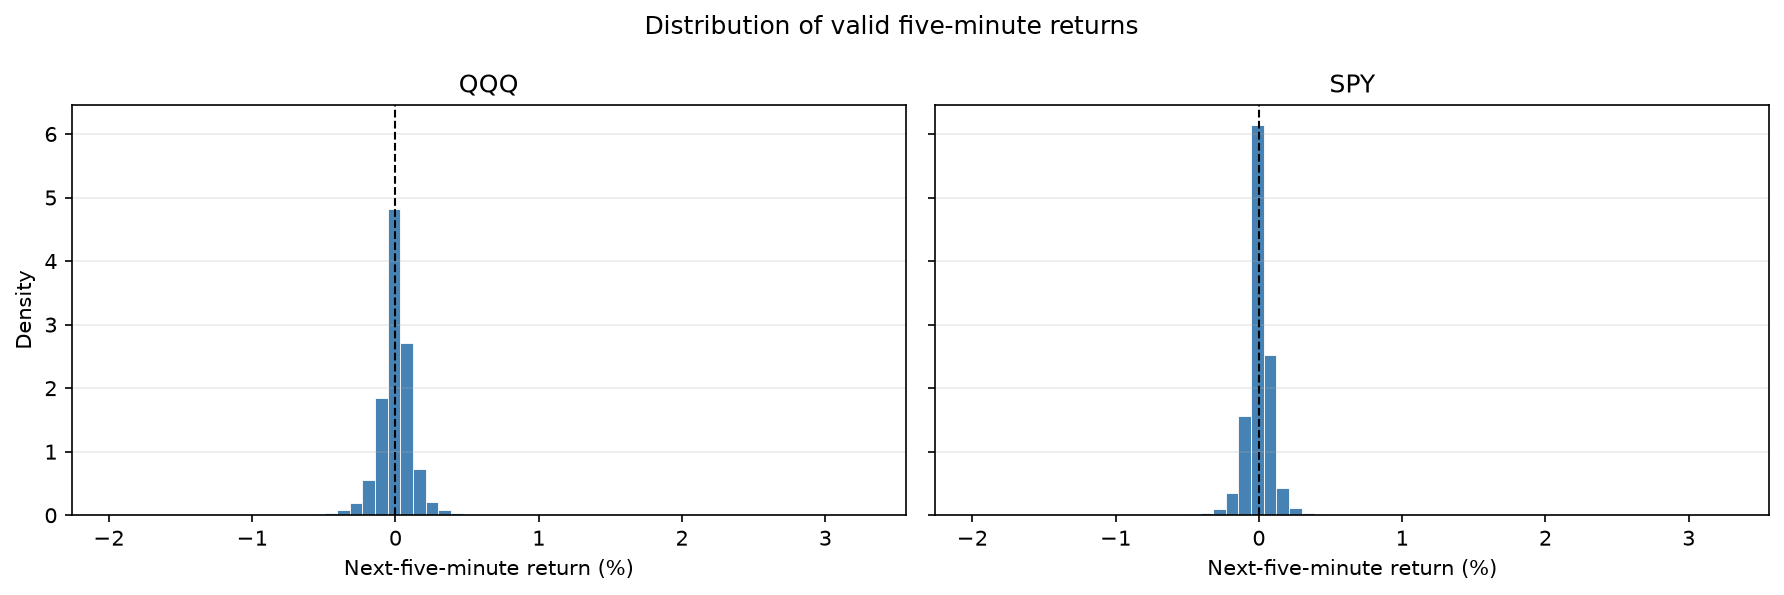

In [32]:
# Plot valid next-five-minute returns for SPY and QQQ.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
all_returns = pd.concat([
    qqq_model_data["next_return"].dropna() * 100,
    spy_model_data["next_return"].dropna() * 100,
])
bins = np.linspace(all_returns.min(), all_returns.max(), 61)

for ax, (name, df) in zip(axes, [("QQQ", qqq_model_data), ("SPY", spy_model_data)]):
    returns = df["next_return"].dropna() * 100
    ax.hist(returns, bins=bins, density=True, color="steelblue",
            edgecolor="white", linewidth=0.4)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Next-five-minute return (%)")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Density")
fig.suptitle("Distribution of valid five-minute returns")
fig.tight_layout()
plt.show()


### What the plot shows

Both ETFs’ valid five-minute returns are concentrated near zero, with fewer large moves in either direction. QQQ’s distribution is wider than SPY’s, consistent with the larger return standard deviation in the descriptive-statistics table. The histogram gives a useful visual summary, while the descriptive statistics quantify the difference.


## Intraday volatility and volume patterns

These plots show how typical five-minute movement and trading activity change across the session. Volume is scaled by each day’s median volume for that ETF, which makes the daily pattern easier to compare between SPY and QQQ.


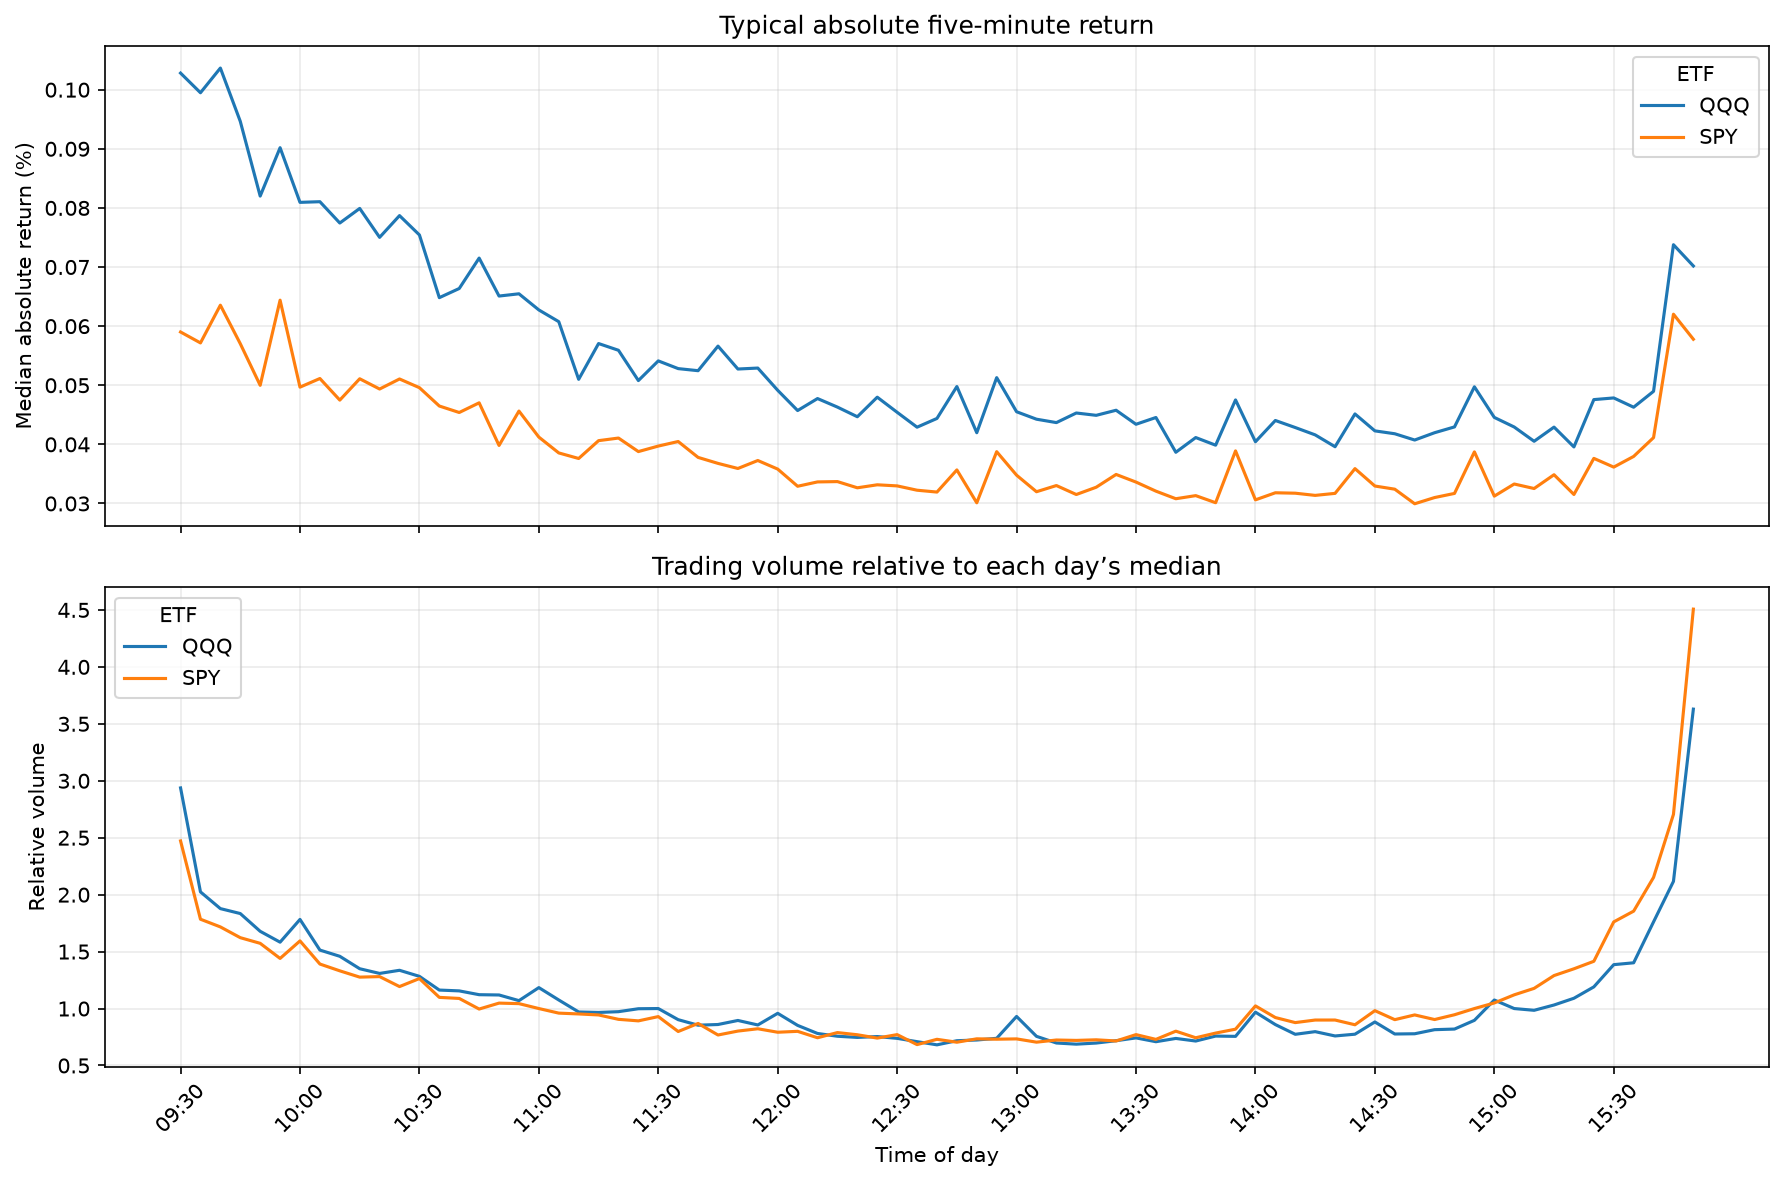

In [33]:
# Compare typical movement and relative volume by time of day.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for name, df in [("QQQ", qqq_model_data), ("SPY", spy_model_data)]:
    valid = df.dropna(subset=["next_return"]).copy()
    valid["time"] = valid["datetime"].dt.strftime("%H:%M")
    valid["absolute_return_pct"] = valid["next_return"].abs() * 100

    # Scale volume against the median volume for the same day.
    daily_median_volume = valid.groupby(valid["datetime"].dt.date)["Volume"].transform("median")
    valid["relative_volume"] = valid["Volume"] / daily_median_volume

    by_time = valid.groupby("time").agg(
        median_absolute_return=("absolute_return_pct", "median"),
        median_relative_volume=("relative_volume", "median"),
    )

    axes[0].plot(by_time.index, by_time["median_absolute_return"], label=name)
    axes[1].plot(by_time.index, by_time["median_relative_volume"], label=name)

axes[0].set_title("Typical absolute five-minute return")
axes[0].set_ylabel("Median absolute return (%)")
axes[1].set_title("Trading volume relative to each day’s median")
axes[1].set_ylabel("Relative volume")
axes[1].set_xlabel("Time of day")

time_labels = by_time.index
axes[1].set_xticks(range(0, len(time_labels), 6))
axes[1].set_xticklabels(time_labels[::6])

for ax in axes:
    ax.legend(title="ETF")
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()


### Initial interpretation

The median absolute return and relative volume vary across the session, showing that market activity is not uniform from open to close. The relative-volume line is normalized within each ETF, so it compares each time of day with that ETF’s usual daily volume rather than comparing raw SPY and QQQ share counts. These patterns describe the data and do not establish that time of day predicts future returns.


## EDA summary and data limitations

### Main findings

The cleaned data covers 1,159 trading days, from 7 March 2022 to 16 October 2026. There are 89,712 five-minute rows for QQQ and 89,729 for SPY in the research datasets. The up and down labels are close to evenly split: 50.66% of valid QQQ targets and 50.54% of valid SPY targets are up moves.

The return histograms are concentrated around zero. QQQ has more variation in five-minute returns than SPY: its standard deviation is about 0.117%, compared with 0.088% for SPY. The time-of-day chart also shows that typical price movement and trading volume change over the session. Both tend to be higher near the open and close, while QQQ has larger typical movements across most of the day.

### Data limitations

Some scheduled five-minute bars are missing from the source data. The target therefore cannot be calculated for every row: 1,382 QQQ rows and 1,387 SPY rows do not have a valid next five-minute bar in the same session. The analysis excludes those rows when calculating target percentages and returns.

This analysis uses price and volume only. It does not include news, company information, or wider market indicators. The charts describe patterns in the historical data, but they do not show that these patterns can predict future prices or produce a profitable strategy. The volume chart is scaled to each day's median, so it compares intraday patterns rather than the ETFs' raw share volumes.


In [34]:
# Make a simple baseline that always predicts the most common training label.
baseline_rows = []

for name, df in [("QQQ", qqq_model_data), ("SPY", spy_model_data)]:
    valid = df.dropna(subset=["target"]).copy()
    valid["date"] = valid["datetime"].dt.date
    trading_days = sorted(valid["date"].unique())

    # Use the first 80% of dates for training and the later dates for testing.
    split_index = int(len(trading_days) * 0.8)
    test_start_date = trading_days[split_index]
    train = valid[valid["date"] < test_start_date]
    test = valid[valid["date"] >= test_start_date]

    # Find the most common target in the training data.
    majority_class = train["target"].astype(int).mode()[0]

    # The baseline predicts that class for every test row.
    accuracy = (test["target"].astype(int) == majority_class).mean() * 100
    test_up_rate = (test["target"] == 1).mean() * 100

    baseline_rows.append({
        "ETF": name,
        "Training targets": len(train),
        "Test targets": len(test),
        "Test starts": str(test_start_date),
        "Predicted class": "Up (1)" if majority_class == 1 else "Down/unchanged (0)",
        "Test accuracy (%)": accuracy,
        "Test up labels (%)": test_up_rate,
    })

baseline_results = pd.DataFrame(baseline_rows).set_index("ETF")
display(baseline_results.round(2))


,Training targets,Test targets,Test starts,Predicted class,Test accuracy (%),Test up labels (%)
ETF,,,,,,
QQQ,70643,17687,2025-11-13,Up (1),50.31,50.31
SPY,70634,17708,2025-11-13,Up (1),49.94,49.94


### Reading the baseline result

This baseline predicts the most common direction in the training period for every observation in the later test period. Its test accuracy gives us a simple comparison point for later models. It uses no market features, so better accuracy from another model would still need to be checked with time-based validation and financial measures before making a trading claim.
